## Params

In [2]:
FEATURES = ["Recency", "Frequency", "Monetary"]
PCA_VAR = 2                     
PCA_VAR_A01 = 0.90                  # ngưỡng của A01 — chỉ để đối chiếu
MIN_SAMPLES_GRID = [4, 6, 8, 10, 15, 20]   # giống A01-DB
EPS_GRID = [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0]   # giống A01-DB
MAX_NOISE = 0.05                    # điều kiện chọn: nhiễu tối đa 5% số khách
MIN_CLUSTERS = 2                    # điều kiện chọn: ít nhất 2 cụm (không tính nhiễu)

## Import thư viện và đọc dữ liệu

In [3]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

def find(rel):
    # Tự tìm file trong repo, không phụ thuộc nơi mở notebook
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01-DB, A02-KM), không sao chép thêm
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:** 4.327 khách, 3 biến RFM, không thiếu giá trị, `CustomerID` không trùng. Phân phối lệch phải mạnh (Monetary median 657,9, max 278.748; Frequency median 2, max 206). Đây là file làm sạch cũ của nhóm, không phải RFM tính thẳng từ raw (xem lưu ý chi tiết ở A02-KM): A01-DB, A02-KM và A04-DB so sánh được với nhau vì cùng một file.

## Chuẩn hóa và PCA giữ 95% phương sai

DBSCAN dựa trên khoảng cách nên phải scale. Không dùng log1p vì thuộc nhánh B.

In [4]:
X_scaled = StandardScaler().fit_transform(X)

In [5]:
pca_full = PCA(svd_solver="full").fit(X_scaled)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n_pc = PCA_VAR
n_pc_a01 = int(np.searchsorted(cum, PCA_VAR_A01) + 1)
pca_a03 = PCA(n_components=n_pc, svd_solver="full")
Z = pca_a03.fit_transform(X_scaled)               # A04
pca_a01 = PCA(n_components=n_pc_a01, svd_solver="full")
Z_a01 = pca_a01.fit_transform(X_scaled)      # A01 dựng lại
print("Phương sai tích lũy:", cum.round(4))
print(
    f"Số PC giữ lại: A03 (cố định) = {n_pc} | "
    f"A01 (90%) = {n_pc_a01} | tổng số biến = {X_scaled.shape[1]}"
)
print(
    "Phương sai giữ lại của A03:",
    f"{pca_a03.explained_variance_ratio_.sum():.2%}"
)
print(
    "Không gian đầu vào A03 trùng A01:",
    bool(Z.shape == Z_a01.shape and np.allclose(Z, Z_a01))
)

Phương sai tích lũy: [0.5638 0.8655 1.    ]
Số PC giữ lại: A03 (cố định) = 2 | A01 (90%) = 3 | tổng số biến = 3
Phương sai giữ lại của A03: 86.55%
Không gian đầu vào A03 trùng A01: False


* Kết quả cho thấy A03 giảm dữ liệu từ 3 biến RFM xuống 2 thành phần chính, giữ lại 86,55% tổng phương sai và loại bỏ 13,45% phương sai còn lại. Trong khi đó, A01 cần giữ cả 3 thành phần để đáp ứng ngưỡng phương sai tích lũy 90%.

* Do số thành phần khác nhau, không gian đầu vào của A03 không trùng với A01. Việc giảm chiều có thể làm thay đổi khoảng cách và mật độ giữa các điểm, từ đó ảnh hưởng đến kết quả phân cụm DBSCAN. Tuy nhiên, chưa thể kết luận A03 tốt hơn hay kém hơn A01 chỉ từ tỷ lệ phương sai giữ lại; cần so sánh thêm số cụm, tỷ lệ nhiễu và các chỉ số đánh giá phân cụm.

## Chọn eps bằng đồ thị k-distance

Với mỗi `min_samples`, tính khoảng cách từ mỗi khách đến láng giềng thứ `min_samples` (tính cả chính nó, giống cách DBSCAN đếm), sắp xếp tăng dần. Điểm bẻ cong mạnh gợi ý eps.

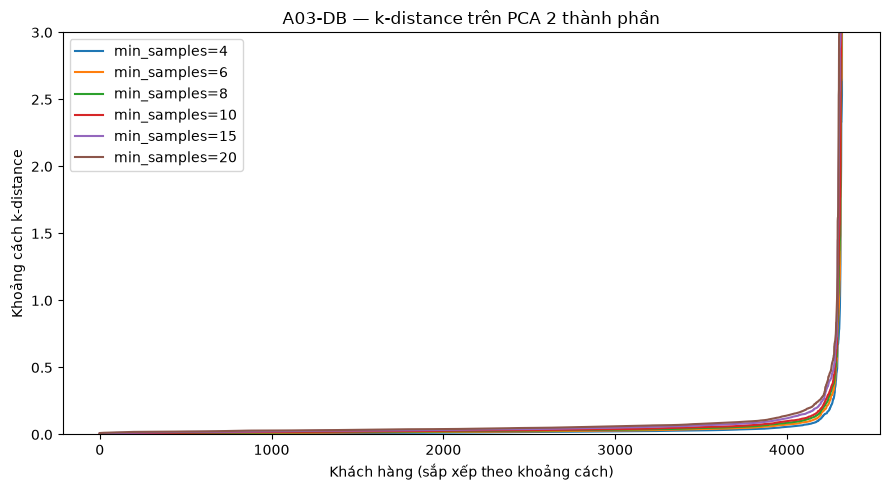

,4,6,8,10,15,20
P50,0.015,0.021,0.025,0.029,0.036,0.042
P90,0.046,0.060,0.072,0.080,0.097,0.112
P95,0.074,0.093,0.110,0.123,0.156,0.184
P99,0.363,0.443,0.495,0.550,0.640,0.721


In [6]:
from sklearn.neighbors import NearestNeighbors

kdist = {}
for ms in MIN_SAMPLES_GRID:
    d = (
        NearestNeighbors(n_neighbors=ms)
        .fit(Z)
        .kneighbors(Z)[0][:, -1]
    )
    kdist[ms] = np.sort(d)

fig, ax = plt.subplots(figsize=(9, 5))
for ms, d in kdist.items():
    ax.plot(d, label=f"min_samples={ms}")

ax.set_ylim(0, 3)
ax.set_xlabel("Khách hàng (sắp xếp theo khoảng cách)")
ax.set_ylabel("Khoảng cách k-distance")
ax.set_title("A03-DB — k-distance trên PCA 2 thành phần")
ax.legend()

plt.tight_layout()
FIG.mkdir(parents=True, exist_ok=True)
plt.savefig(FIG / "A03_k_distance.png", dpi=150, bbox_inches="tight")
plt.show()

display(
    pd.DataFrame(
        {
            ms: np.quantile(d, [0.5, 0.9, 0.95, 0.99])
            for ms, d in kdist.items()
        },
        index=["P50", "P90", "P95", "P99"]
    ).round(3)
)

* Các đường k-distance đều tăng chậm ở phần lớn dữ liệu và tăng mạnh ở cuối, cho thấy phần lớn khách hàng nằm trong các vùng có mật độ cao, trong khi một số ít có khoảng cách tới láng giềng lớn, có khả năng trở thành điểm nhiễu.

* Khi min_samples tăng từ 4 lên 20, các phân vị khoảng cách cũng tăng. Cụ thể, P95 tăng từ 0,074 lên 0,184, còn P99 tăng từ 0,363 lên 0,721. Vì vậy, với min_samples lớn hơn, thường cần eps lớn hơn để đáp ứng yêu cầu mật độ.

* Khoảng cách tăng rõ rệt từ P95 đến P99 cho thấy phần đuôi dữ liệu khá thưa. Các giá trị eps từ 0,1 đến 0,7 trong lưới hiện tại đáng được khảo sát kỹ; các mức lớn hơn giúp kiểm tra khả năng giảm nhiễu nhưng có thể làm các cụm hợp nhất

## Quét lưới eps × min_samples

Silhouette và DBI chỉ tính trên khách **không bị gán nhiễu** và chỉ khi có ≥ 2 cụm.

In [7]:
def run_dbscan(Zs, eps, ms):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(Zs)
    mask = labels != -1
    sizes = pd.Series(labels[mask]).value_counts()
    k = len(sizes)

    row = {
        "min_samples": ms,
        "eps": eps,
        "n_clusters": k,
        "noise_pct": 100 * (~mask).mean(),
        "largest_pct": 100 * sizes.iloc[0] / len(Zs) if k else np.nan,
        "smallest": int(sizes.iloc[-1]) if k else 0,
        "silhouette": np.nan,
        "dbi": np.nan,
    }

    # Chỉ đánh giá trên các điểm không phải nhiễu
    if 2 <= k < mask.sum():
        row["silhouette"] = silhouette_score(Zs[mask], labels[mask])
        row["dbi"] = davies_bouldin_score(Zs[mask], labels[mask])

    return row, labels


# Z là dữ liệu PCA 2 thành phần của A03
pairs = [(e, m) for m in MIN_SAMPLES_GRID for e in EPS_GRID]
runs = [run_dbscan(Z, e, m) for e, m in pairs]

grid = pd.DataFrame([row for row, _ in runs])
labels_a03 = {
    pair: labels
    for pair, (_, labels) in zip(pairs, runs)
}

eligible = (
    (grid["n_clusters"] >= MIN_CLUSTERS)
    & (grid["noise_pct"] <= MAX_NOISE * 100)
)

print("Số cấu hình đã chạy:", len(grid))
print(
    "Số cấu hình có >= 2 cụm:",
    int((grid["n_clusters"] >= 2).sum())
)
print(
    "Số cấu hình đạt điều kiện số cụm và nhiễu:",
    int(eligible.sum())
)

display(
    grid.loc[eligible]
    .sort_values("silhouette", ascending=False)
    .head(10)
    .round(4)
)

Số cấu hình đã chạy: 54
Số cấu hình có >= 2 cụm: 13
Số cấu hình đạt điều kiện số cụm và nhiễu: 10


,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
34,10,1.5,2,0.3235,99.4453,10,0.8362,0.2146
24,8,1.0,2,0.3929,99.3991,9,0.8297,0.2054
6,4,1.0,2,0.3467,99.3991,11,0.8293,0.2202
15,6,1.0,2,0.3698,99.3991,10,0.8272,0.2156
5,4,0.7,3,0.4160,99.3760,4,0.8150,0.5971
29,10,0.3,2,1.1786,98.6134,9,0.6732,0.2837
10,6,0.2,2,1.6409,98.2667,4,0.6681,0.2620
18,8,0.1,4,3.7439,93.1361,8,0.4001,0.4255
9,6,0.1,4,3.1893,93.4597,10,0.3951,0.4832
0,4,0.1,4,2.8888,93.5290,8,0.3389,0.3858


Trong 54 cấu hình DBSCAN được khảo sát trên dữ liệu PCA 2 thành phần, có 13 cấu hình tạo được ít nhất 2 cụm và 10 cấu hình đáp ứng thêm điều kiện tỷ lệ nhiễu không quá 5%. Cấu hình eps = 1.5, min_samples = 10 đạt Silhouette cao nhất (0,8362), DBI đạt 0,2146 và tỷ lệ nhiễu khoảng 0,32%. Tuy nhiên, cụm lớn nhất chiếm tới 99,45% tổng số khách hàng, trong khi cụm nhỏ chỉ có 10 khách hàng. Các cấu hình đủ điều kiện còn lại cũng có cụm lớn nhất chiếm trên 93%, cho thấy kết quả phân cụm mất cân đối. Vì vậy, dù một số cấu hình đạt chỉ số đánh giá tốt, A03 chủ yếu tách một nhóm khách hàng rất nhỏ khỏi nhóm chính; cần xem xét thêm đặc điểm RFM của các cụm để đánh giá ý nghĩa thực tế đối với bài toán phân khúc khách hàng.

## Chọn cấu hình

Cùng quy tắc A01-DB (đặt trước khi xem kết quả): ≥ 2 cụm, nhiễu ≤ 5% số khách, chọn **Silhouette cao nhất** trong các cấu hình thỏa.

In [8]:
valid = grid[(grid["n_clusters"] >= MIN_CLUSTERS) & (grid["noise_pct"] <= MAX_NOISE * 100)]
best = valid.sort_values("silhouette", ascending=False).iloc[0]
print("Cấu hình được chọn:")
print(best.to_string())

Cấu hình được chọn:
min_samples    10.000000
eps             1.500000
n_clusters      2.000000
noise_pct       0.323550
largest_pct    99.445343
smallest       10.000000
silhouette      0.836199
dbi             0.214579


## Hồ sơ cụm

Nhãn `-1` là nhiễu. Cột `Monetary_share_pct` là tỷ trọng tổng Monetary của nhóm.

In [9]:
labels = labels_a03[(float(best["eps"]), int(best["min_samples"]))]
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
    Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum")
prof.round(1)

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
-1,14,3.0,61.0,81885.2,0.3,18.0
0,4303,52.0,2.0,655.6,99.4,77.0
1,10,4.0,50.5,44340.6,0.2,5.0


Kết quả cho thấy DBSCAN chia khách hàng thành hai cụm và một nhóm nhiễu, với quy mô rất mất cân đối. Cụm 0 có 4.303 khách hàng, chiếm khoảng 99,4% và đóng góp 77% tổng Monetary, có Recency khoảng 52 ngày, Frequency bằng 2 và Monetary khoảng 655,6, thể hiện nhóm mua ít thường xuyên và giá trị chi tiêu thấp hơn các nhóm còn lại. Cụm 1 chỉ có 10 khách hàng, chiếm khoảng 0,2% nhưng đóng góp 5% tổng Monetary; Recency khoảng 4 ngày, Frequency khoảng 50,5 và Monetary khoảng 44.340,6 cho thấy đây là nhóm mua gần đây, thường xuyên và có giá trị cao. Nhóm nhiễu gồm 14 khách hàng, chỉ chiếm khoảng 0,3% nhưng đóng góp tới 18% tổng Monetary, cho thấy các điểm bị xem là nhiễu có thể là khách hàng giá trị rất cao cần được phân tích riêng. Nhìn chung, A03 chủ yếu tách các khách hàng có hành vi nổi bật khỏi nhóm khách hàng đại trà, thay vì tạo ra các phân khúc có quy mô tương đối cân đối.

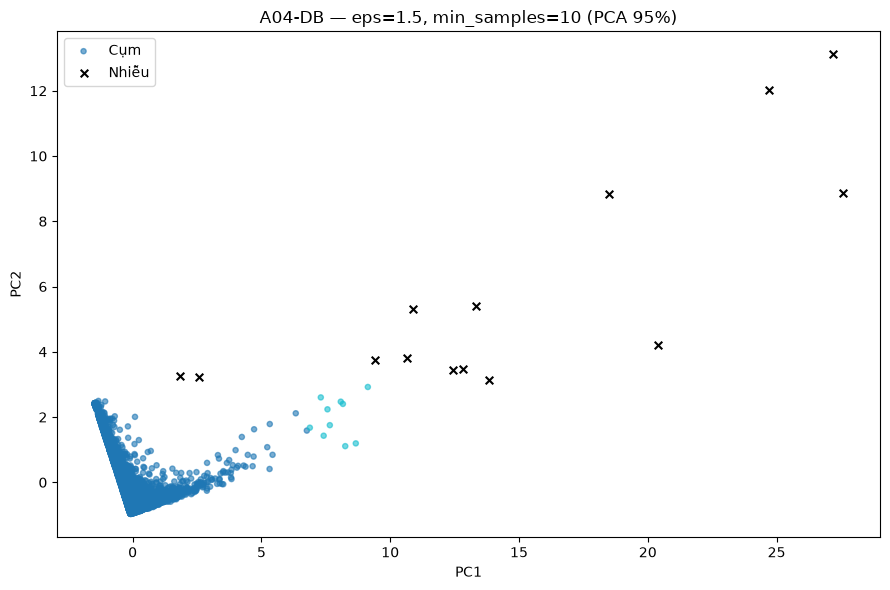

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
noise = labels == -1
ax.scatter(Z[~noise, 0], Z[~noise, 1], c=labels[~noise], cmap="tab10", s=14, alpha=0.6, label="Cụm")
ax.scatter(Z[noise, 0], Z[noise, 1], c="black", marker="x", s=30, label="Nhiễu")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"A04-DB — eps={best['eps']}, min_samples={int(best['min_samples'])} (PCA 95%)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "dbscan_clusters_pca.png", dpi=150)
plt.show()

**Nhận xét:** Gần như toàn bộ khách dồn thành một khối ở gốc tọa độ, còn các cụm nhỏ và điểm nhiễu rải dọc đuôi PC1 — DBSCAN chỉ tách phần đuôi ngoại lai.

## Lưu kết quả

In [11]:
grid.to_csv(OUT / "dbscan_a03_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "dbscan_a03_labels.csv", index=False)
params = {"experiment": "A03-DB", "features": FEATURES, "scaler": "StandardScaler",
          "pca_mode": "fixed_n_components", "n_components": int(n_pc),
          "pca_explained_variance_ratio": float(pca_a03.explained_variance_ratio_.sum()),
          "eps": float(best["eps"]), "min_samples": int(best["min_samples"]),
          "n_clusters": int(best["n_clusters"]), "noise_pct": float(best["noise_pct"]),
          "silhouette_non_noise": float(best["silhouette"]), "dbi_non_noise": float(best["dbi"])}
with (OUT / "dbscan_a03_params.json").open("w", encoding="utf8") as f:
    json.dump(params, f, ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['dbscan_a03_grid.csv', 'dbscan_a03_labels.csv', 'dbscan_a03_params.json', 'dbscan_a04_grid.csv', 'dbscan_a04_labels.csv', 'dbscan_a04_params.json']
